# ML Zoomcamp 2026 - Homework 6: Decision Trees and Ensemble Learning

Goal: predict `fuel_efficiency_mpg` with tree-based models: a decision tree, a random forest and XGBoost.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

%matplotlib inline

## Library versions

The reference answers were computed with scikit-learn 1.7.2 and XGBoost 3.2.0. Random forests can give slightly different results across versions even with the same seed (with scikit-learn 1.9.1, Q3 changes), so this notebook pins them: see `requirements.txt` in this folder.

In [2]:
import sklearn

print('scikit-learn:', sklearn.__version__)
print('xgboost:', xgb.__version__)

scikit-learn: 1.7.2
xgboost: 3.2.0


## Prepare the dataset

Fill missing values with zeros, split with the exact calls from the homework, and vectorize. `DictVectorizer` one-hot encodes the categorical columns; numerical columns pass through unchanged.

In [3]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df = pd.read_csv(url)

print('missing before:', df.isnull().sum()[lambda s: s > 0].to_dict())
df = df.fillna(0)
print('missing after: ', df.isnull().sum().sum())

missing before: {'horsepower': 877, 'acceleration': 264}
missing after:  0


In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values

# The target must not be part of the features
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']

len(df_train), len(df_val)

(6000, 2000)

In [5]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

feature_names = list(dv.get_feature_names_out())
feature_names

['acceleration',
 'drivetrain=All-wheel drive',
 'drivetrain=Front-wheel drive',
 'drivetrain=Rear-wheel drive',
 'engine_displacement',
 'fuel_type=Diesel',
 'fuel_type=Gasoline',
 'fuel_type=Hybrid',
 'horsepower',
 'model_year',
 'num_cylinders',
 'num_doors',
 'origin=Asia',
 'origin=Europe',
 'origin=USA',
 'vehicle_weight']

## Q1. Which feature does a depth-1 tree split on?

With `max_depth=1` the tree makes exactly one split: the one that reduces the error the most.

In [6]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=feature_names))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



## Q2. Random forest with 10 trees

A random forest averages many trees, each trained on a random sample of the data and features.

In [7]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

root_mean_squared_error(y_val, rf.predict(X_val))

1.837054054730018

## Q3. Number of trees (`n_estimators`)

RMSE compared with 3 decimal places.

In [8]:
scores_n = {}
for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    scores_n[n] = round(root_mean_squared_error(y_val, rf.predict(X_val)), 3)
    print(n, scores_n[n])

10 1.837


50 1.772


100 1.768


150 1.769


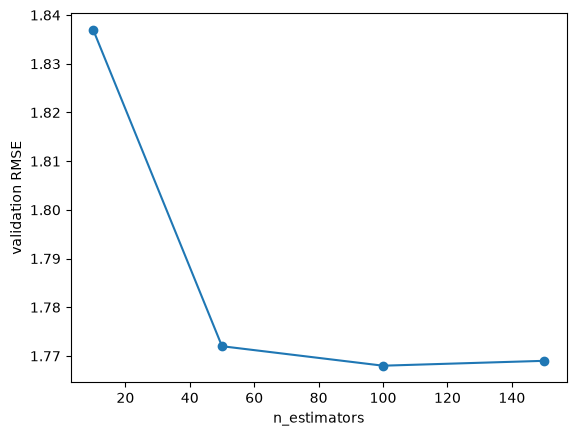

In [9]:
plt.plot(list(scores_n.keys()), list(scores_n.values()), marker='o')
plt.xlabel('n_estimators')
plt.ylabel('validation RMSE')
plt.show()

## Q4. Best `max_depth`

For each depth, try all the values of `n_estimators` and average the RMSE.

In [10]:
rows = []
for depth in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        rows.append((depth, n, root_mean_squared_error(y_val, rf.predict(X_val))))

df_scores = pd.DataFrame(rows, columns=['max_depth', 'n_estimators', 'rmse'])
df_scores.pivot(index='n_estimators', columns='max_depth', values='rmse').round(4)

max_depth,10,15,20,25
n_estimators,,,,
10,1.7837,1.8299,1.8410,1.8368
50,1.7486,1.7711,1.7731,1.7721
100,1.7448,1.7679,1.7692,1.7684
150,1.7445,1.7669,1.7697,1.7680


In [11]:
df_scores.groupby('max_depth')['rmse'].mean().round(5)

max_depth
10    1.75540
15    1.78395
20    1.78824
25    1.78632
Name: rmse, dtype: float64

## Q5. Feature importance

`feature_importances_` measures how much each feature reduces the error across all the splits of the forest.

In [12]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
importances.round(4)

model_year                      0.2960
vehicle_weight                  0.2039
fuel_type=Gasoline              0.1607
horsepower                      0.0780
engine_displacement             0.0610
acceleration                    0.0552
origin=USA                      0.0421
drivetrain=Front-wheel drive    0.0201
num_doors                       0.0194
fuel_type=Diesel                0.0170
fuel_type=Hybrid                0.0158
drivetrain=All-wheel drive      0.0077
num_cylinders                   0.0073
origin=Asia                     0.0064
drivetrain=Rear-wheel drive     0.0058
origin=Europe                   0.0035
dtype: float64

In [13]:
importances[['vehicle_weight', 'horsepower', 'acceleration', 'engine_displacement']].round(4)

vehicle_weight         0.2039
horsepower             0.0780
acceleration           0.0552
engine_displacement    0.0610
dtype: float64

## Q6. XGBoost: `eta` 0.3 vs 0.1

Gradient boosting trains trees one after another, each correcting the errors of the previous ones. `eta` is the learning rate: how much each new tree contributes. The watchlist reports the RMSE on train and validation after each round.

In [14]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)
watchlist = [(dtrain, 'train'), (dval, 'val')]


def train_xgb(eta):
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }
    history = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist,
                      evals_result=history, verbose_eval=False)
    return model, history['val']['rmse']

In [15]:
model_03, val_03 = train_xgb(0.3)
model_01, val_01 = train_xgb(0.1)

for eta, val in [(0.3, val_03), (0.1, val_01)]:
    print(f'eta={eta}: final RMSE={val[-1]:.4f}, best RMSE={min(val):.4f} at round {int(np.argmin(val)) + 1}')

eta=0.3: final RMSE=1.8265, best RMSE=1.7320 at round 11
eta=0.1: final RMSE=1.7248, best RMSE=1.7122 at round 40


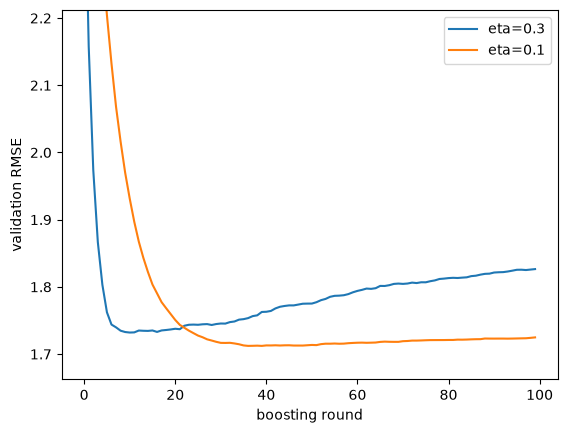

In [16]:
plt.plot(val_03, label='eta=0.3')
plt.plot(val_01, label='eta=0.1')
plt.xlabel('boosting round')
plt.ylabel('validation RMSE')
plt.ylim(min(val_03 + val_01) - 0.05, min(val_03 + val_01) + 0.5)
plt.legend()
plt.show()